# 01 — A simple Variational Autoencoder (VAE)

This notebook trains a small VAE on MNIST. The encoder maps each image to a Gaussian latent distribution, the reparameterization trick makes sampling differentiable, and the decoder reconstructs the image. The objective combines reconstruction loss and KL divergence.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Load MNIST
Images are scaled to `[0, 1]`, which matches the decoder's sigmoid output.

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)
len(train_data), len(test_data)

(60000, 10000)

## Define the VAE
The encoder predicts `mu` and `log_var`. We sample `z = mu + sigma * epsilon`, where `epsilon` is standard normal noise. The decoder maps the latent vector back to 784 pixel probabilities.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 400),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_log_var = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 28 * 28),
            nn.Sigmoid(),
        )

    def encode(self, x):
        hidden = self.encoder(x.flatten(start_dim=1))
        return self.fc_mu(hidden), self.fc_log_var(hidden)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        reconstruction = self.decode(z)
        return reconstruction, mu, log_var

model = VAE(latent_dim=20).to(device)
sum(p.numel() for p in model.parameters() if p.requires_grad)

652824

## Loss and training
Binary cross entropy measures pixel reconstruction error. The KL term encourages each encoded distribution to stay near a standard normal prior. Both terms are summed over pixels and latent dimensions, then averaged over the batch.

In [4]:
def vae_loss(reconstruction, x, mu, log_var):
    x = x.view(-1, 1, 28, 28)
    reconstruction_loss = F.binary_cross_entropy(reconstruction, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.square() - log_var.exp())
    return (reconstruction_loss + kl_loss) / x.size(0), reconstruction_loss / x.size(0), kl_loss / x.size(0)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(3)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, _ in loader:
            images = images.to(device)
            if training:
                optimizer.zero_grad()
            reconstruction, mu, log_var = model(images)
            loss, recon_loss, kl = vae_loss(reconstruction, images, mu, log_var)
            if training:
                loss.backward()
                optimizer.step()
            totals += torch.tensor([loss.item(), recon_loss.item(), kl.item()]) * images.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50
for epoch in range(1, epochs + 1):
    train_metrics = run_epoch(train_loader, training=True)
    test_metrics = run_epoch(test_loader, training=False)
    print(f'Epoch {epoch:02d} | train loss {train_metrics[0]:.2f} '          f'(recon {train_metrics[1]:.2f}, KL {train_metrics[2]:.2f}) | '          f'test loss {test_metrics[0]:.2f}')

Epoch 01 | train loss 163.42 (recon 147.49, KL 15.93) | test loss 126.90
Epoch 02 | train loss 121.11 (recon 98.40, KL 22.70) | test loss 115.82
Epoch 03 | train loss 114.53 (recon 90.38, KL 24.15) | test loss 111.84
Epoch 04 | train loss 111.64 (recon 87.02, KL 24.62) | test loss 109.81
Epoch 05 | train loss 109.86 (recon 84.99, KL 24.87) | test loss 108.32
Epoch 06 | train loss 108.64 (recon 83.60, KL 25.04) | test loss 107.44
Epoch 07 | train loss 107.76 (recon 82.64, KL 25.12) | test loss 106.82
Epoch 08 | train loss 107.09 (recon 81.86, KL 25.23) | test loss 106.46
Epoch 09 | train loss 106.58 (recon 81.29, KL 25.30) | test loss 105.71
Epoch 10 | train loss 106.15 (recon 80.79, KL 25.36) | test loss 105.78
Epoch 11 | train loss 105.77 (recon 80.39, KL 25.39) | test loss 105.29
Epoch 12 | train loss 105.48 (recon 80.06, KL 25.42) | test loss 105.07
Epoch 13 | train loss 105.26 (recon 79.80, KL 25.46) | test loss 105.01
Epoch 14 | train loss 104.97 (recon 79.51, KL 25.46) | test los

## Compare originals and reconstructions

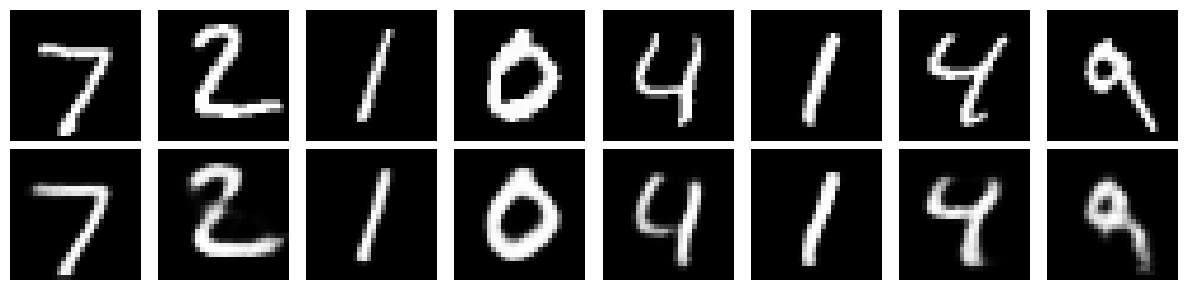

In [5]:
model.eval()
images, _ = next(iter(test_loader))
images = images[:8].to(device)
with torch.no_grad():
    reconstructions, _, _ = model(images)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray')
    axes[1, i].imshow(reconstructions[i, 0].cpu(), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].axis('off')
axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout()
plt.show()

## Generate new digits
Sampling latent vectors from the standard normal prior gives the decoder new examples.

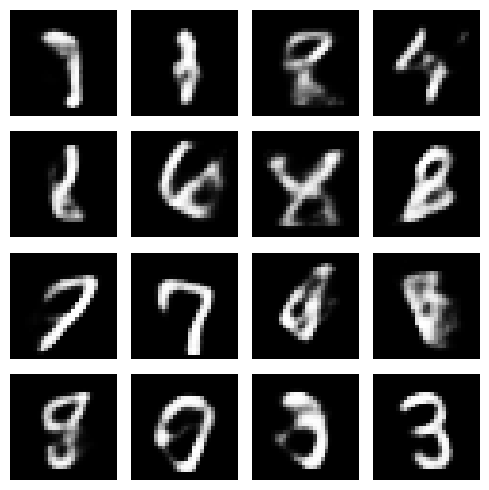

In [6]:
with torch.no_grad():
    samples = model.decode(torch.randn(16, model.latent_dim, device=device)).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image[0], cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()